In [10]:
from pathlib import Path
import json
import hashlib

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

In [11]:
DATA_DIR = Path("../data/raw")
PROCESSED_DIR = Path("../data/processed")

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

IMAGE_SIZE = (224, 224)
RANDOM_STATE = 42

VALID_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

In [12]:
class_folders = sorted([
    folder
    for folder in DATA_DIR.iterdir()
    if folder.is_dir()
])

class_names = [folder.name for folder in class_folders]

print("Number of classes:", len(class_names))
print("Classes:", class_names)

Number of classes: 4
Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


In [13]:
images = []
labels = []
image_paths = []
invalid_files = []

for folder in class_folders:

    for path in folder.iterdir():

        if not path.is_file():
            continue

        if path.suffix.lower() not in VALID_EXTENSIONS:
            invalid_files.append(str(path))
            continue

        try:
            image = cv2.imread(str(path))

            if image is None:
                raise ValueError("Cannot read image")

            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

            images.append(image)
            labels.append(folder.name)
            image_paths.append(str(path))

        except Exception as error:
            invalid_files.append(str(path))
            print(f"Error: {path} - {error}")

print("Loaded images:", len(images))
print("Invalid files:", len(invalid_files))

Loaded images: 7023
Invalid files: 0


In [14]:
hashes = {}
duplicate_indices = []
conflicting_duplicates = []

for i, image in enumerate(images):

    image_hash = hashlib.sha256(image.tobytes()).hexdigest()

    if image_hash in hashes:
        original_index = hashes[image_hash]
        duplicate_indices.append(i)

        if labels[i] != labels[original_index]:
            conflicting_duplicates.append(i)
    else:
        hashes[image_hash] = i

print("Duplicate images:", len(duplicate_indices))
print("Conflicting labels:", len(conflicting_duplicates))

Duplicate images: 426
Conflicting labels: 0


In [15]:
for i in duplicate_indices[:10]:

    image_hash = hashlib.sha256(images[i].tobytes()).hexdigest()
    original_index = hashes[image_hash]

    print("Original:", image_paths[original_index])
    print("Duplicate:", image_paths[i])
    print("Labels:", labels[original_index], "|", labels[i])
    print("-" * 40)

Original: ..\data\raw\glioma\Te-gl_0024.jpg
Duplicate: ..\data\raw\glioma\Te-gl_0029.jpg
Labels: glioma | glioma
----------------------------------------
Original: ..\data\raw\meningioma\Te-me_0010.jpg
Duplicate: ..\data\raw\meningioma\Te-me_0031.jpg
Labels: meningioma | meningioma
----------------------------------------
Original: ..\data\raw\meningioma\Te-me_0071.jpg
Duplicate: ..\data\raw\meningioma\Te-me_0073.jpg
Labels: meningioma | meningioma
----------------------------------------
Original: ..\data\raw\meningioma\Te-meTr_0002.jpg
Duplicate: ..\data\raw\meningioma\Te-me_0140.jpg
Labels: meningioma | meningioma
----------------------------------------
Original: ..\data\raw\meningioma\Te-me_0106.jpg
Duplicate: ..\data\raw\meningioma\Te-me_0143.jpg
Labels: meningioma | meningioma
----------------------------------------
Original: ..\data\raw\meningioma\Te-me_0110.jpg
Duplicate: ..\data\raw\meningioma\Te-me_0145.jpg
Labels: meningioma | meningioma
-----------------------------------

In [16]:
duplicate_set = set(duplicate_indices)

clean_images = [
    image
    for i, image in enumerate(images)
    if i not in duplicate_set
]

clean_labels = [
    label
    for i, label in enumerate(labels)
    if i not in duplicate_set
]

print("Before cleaning:", len(images))
print("After cleaning:", len(clean_images))
print("Removed duplicates:", len(duplicate_set))

Before cleaning: 7023
After cleaning: 6597
Removed duplicates: 426


In [17]:
X = np.array([
    cv2.resize(image, IMAGE_SIZE)
    for image in clean_images
], dtype=np.uint8)

y = np.array(clean_labels)

print("Images shape:", X.shape)
print("Labels shape:", y.shape)

Images shape: (6597, 224, 224, 3)
Labels shape: (6597,)


In [18]:
rng = np.random.default_rng(RANDOM_STATE)

indices = rng.permutation(len(X))

X = X[indices]
y = y[indices]

print("Dataset shuffled successfully!")

Dataset shuffled successfully!


pituitary     1740
notumor       1706
glioma        1620
meningioma    1531
Name: count, dtype: int64


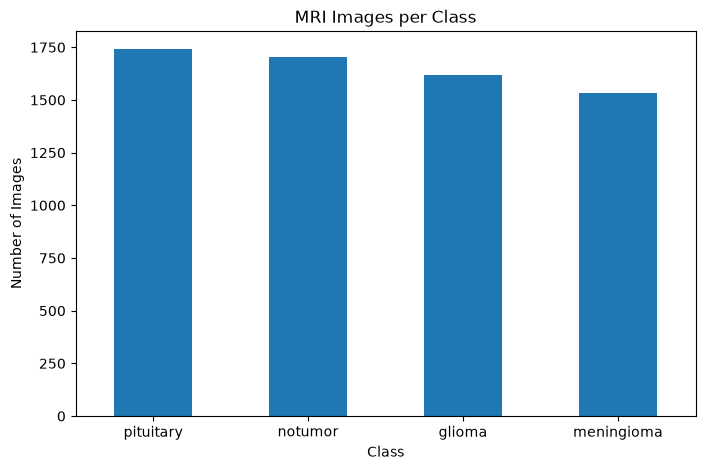

In [19]:
class_counts = pd.Series(y).value_counts()

print(class_counts)

plt.figure(figsize=(8, 5))

class_counts.plot(kind="bar")

plt.title("MRI Images per Class")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)

plt.show()

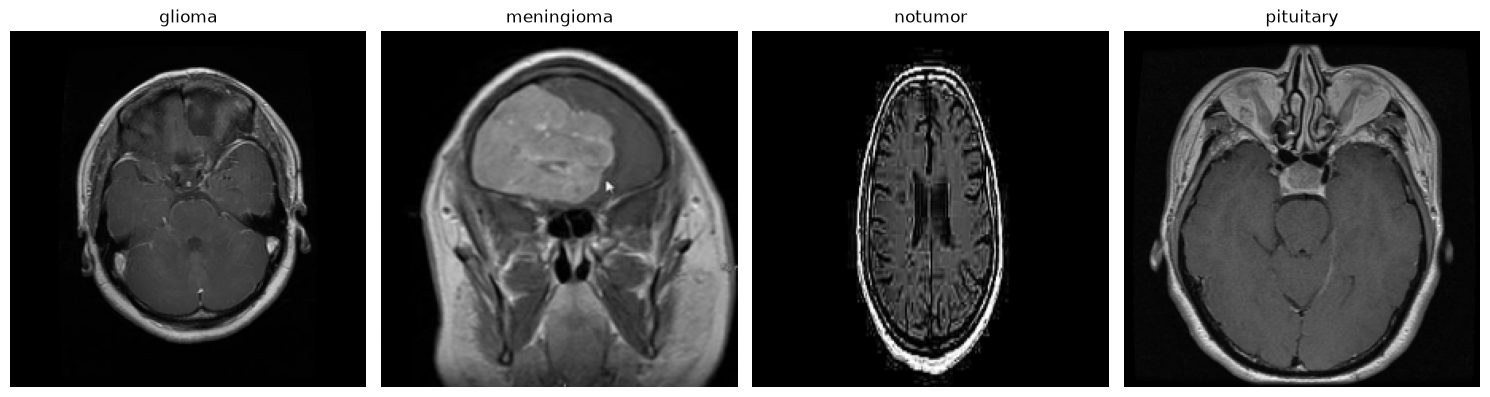

In [20]:
fig, axes = plt.subplots(
    1,
    len(class_names),
    figsize=(15, 4)
)

axes = np.atleast_1d(axes)

for i, class_name in enumerate(class_names):

    class_indices = np.where(y == class_name)[0]
    sample_index = class_indices[0]

    axes[i].imshow(X[sample_index])
    axes[i].set_title(class_name)
    axes[i].axis("off")

plt.tight_layout()
plt.show()

In [21]:
encoder = LabelEncoder()

y_encoded = encoder.fit_transform(y)

label_mapping = {
    int(i): name
    for i, name in enumerate(encoder.classes_)
}

print("Label mapping:", label_mapping)

with open(PROCESSED_DIR / "labels.json", "w") as file:
    json.dump(label_mapping, file, indent=4)

Label mapping: {0: np.str_('glioma'), 1: np.str_('meningioma'), 2: np.str_('notumor'), 3: np.str_('pituitary')}


In [22]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y_encoded,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y_encoded
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=y_temp
)

print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test))

Training: 4617
Validation: 990
Testing: 990


In [23]:
train_counts = pd.Series(y_train).value_counts().sort_index()

for class_id, count in train_counts.items():
    print(f"{encoder.classes_[class_id]}: {count}")

imbalance_ratio = train_counts.max() / train_counts.min()

print("Imbalance ratio:", round(imbalance_ratio, 2))

glioma: 1134
meningioma: 1071
notumor: 1194
pituitary: 1218
Imbalance ratio: 1.14


In [24]:
X_train = X_train.astype("float32") / 255.0
X_val = X_val.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

print("Min:", X_train.min())
print("Max:", X_train.max())

Min: 0.0
Max: 1.0


In [25]:
np.savez_compressed(
    PROCESSED_DIR / "train.npz",
    X=X_train,
    y=y_train
)

np.savez_compressed(
    PROCESSED_DIR / "val.npz",
    X=X_val,
    y=y_val
)

np.savez_compressed(
    PROCESSED_DIR / "test.npz",
    X=X_test,
    y=y_test
)

print("Datasets saved successfully!")

Datasets saved successfully!


In [26]:
train_data = np.load(PROCESSED_DIR / "train.npz")
val_data = np.load(PROCESSED_DIR / "val.npz")
test_data = np.load(PROCESSED_DIR / "test.npz")

print("Training images:", train_data["X"].shape)
print("Validation images:", val_data["X"].shape)
print("Testing images:", test_data["X"].shape)

print("Training labels:", train_data["y"].shape)
print("Validation labels:", val_data["y"].shape)
print("Testing labels:", test_data["y"].shape)

print("Day 1 completed successfully!")

Training images: (4617, 224, 224, 3)
Validation images: (990, 224, 224, 3)
Testing images: (990, 224, 224, 3)
Training labels: (4617,)
Validation labels: (990,)
Testing labels: (990,)
Day 1 completed successfully!
